# 05 — Segmentação RFM com K-Means
**Olist Analytics Hub | Etapa 5 de 7**

**Objetivo:** Agrupar os clientes pelo comportamento de compra — há quanto tempo compraram (Recência), quantas vezes (Frequência) e quanto gastaram (Valor Monetário) — para saber com quem vale a pena falar e o que dizer.

---
### Perguntas que este notebook responde
1. Como se distribuem Recência, Frequência e Valor na base?
2. Quantos grupos fazem sentido? (Elbow + silhueta)
3. Qual o perfil de cada segmento e quanto da receita ele representa?
4. Que ação de negócio cabe em cada segmento?

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from src.data_cleaner import load_processed, save_processed
from src.visualizations import setup_style, save_fig, format_brl
from src.config import COLORS, RFM_REFERENCE_DATE, N_CLUSTERS_RFM

setup_style()
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('✓ Ambiente configurado.')

✓ Ambiente configurado.


In [2]:
df = load_processed('orders_enriched')

# Apenas pedidos entregues e com itens associados
delivered = df[df['is_delivered'] & df['revenue'].notna()].copy()

# A data de referência é o dia seguinte ao último pedido entregue
ref_date = pd.Timestamp(RFM_REFERENCE_DATE)
ultimo = delivered['order_purchase_timestamp'].max()
assert ref_date == ultimo.normalize() + pd.Timedelta(days=1), 'Atualize RFM_REFERENCE_DATE em src/config.py'

print(f'Pedidos considerados: {len(delivered):,}')
print(f'Último pedido entregue: {ultimo}')
print(f'Data de referência RFM: {ref_date.date()}')

Pedidos considerados: 96,478
Último pedido entregue: 2018-08-29 15:00:37
Data de referência RFM: 2018-08-30


## 1. Cálculo de Recência, Frequência e Valor

O cálculo é feito por `customer_unique_id`, que identifica a pessoa. O `customer_id` muda a cada pedido, então usá-lo faria todo mundo parecer cliente de uma compra só.

In [3]:
rfm = (
    delivered
    .groupby('customer_unique_id')
    .agg(
        ultima_compra=('order_purchase_timestamp', 'max'),
        frequency=('order_id', 'nunique'),
        monetary=('revenue', 'sum'),
    )
    .reset_index()
)
rfm['recency'] = (ref_date - rfm['ultima_compra']).dt.days
rfm = rfm[['customer_unique_id', 'recency', 'frequency', 'monetary']]

print(f'Clientes: {len(rfm):,}')
display(rfm[['recency', 'frequency', 'monetary']].describe().round(1))

Clientes: 93,358


,recency,frequency,monetary
count,"93,358.00","93,358.00","93,358.00"
mean,237.50,1.00,141.60
std,152.60,0.20,215.70
min,0.00,1.00,0.80
25%,114.00,1.00,47.60
50%,218.00,1.00,89.70
75%,346.00,1.00,154.70
max,713.00,15.00,"13,440.00"


  ✓ Figura salva: 05_distribuicoes_rfm.png


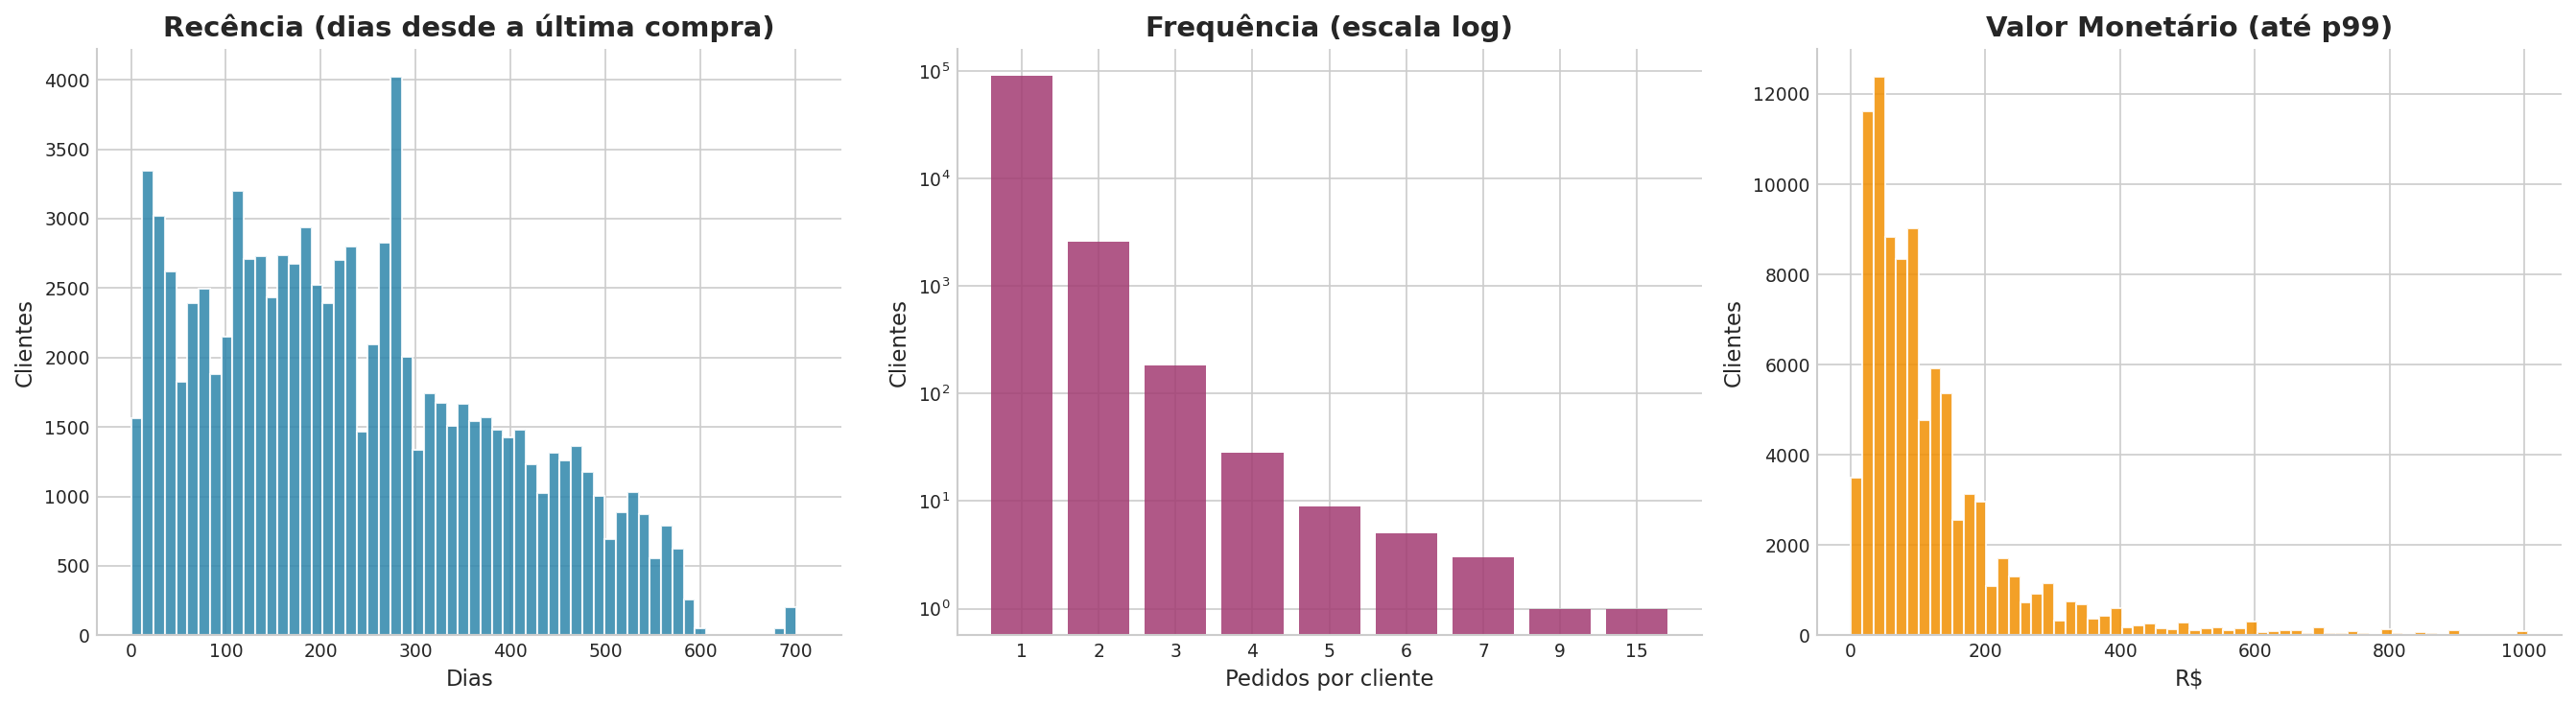

Clientes com 1 pedido: 97.0%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(rfm['recency'], bins=60, color=COLORS['primary'], alpha=0.85, edgecolor='white')
axes[0].set_title('Recência (dias desde a última compra)')
axes[0].set_xlabel('Dias')
axes[0].set_ylabel('Clientes')

freq_dist = rfm['frequency'].value_counts().sort_index()
axes[1].bar(freq_dist.index.astype(str), freq_dist.values, color=COLORS['secondary'], alpha=0.85)
axes[1].set_yscale('log')
axes[1].set_title('Frequência (escala log)')
axes[1].set_xlabel('Pedidos por cliente')
axes[1].set_ylabel('Clientes')

p99 = rfm['monetary'].quantile(0.99)
axes[2].hist(rfm.loc[rfm['monetary'] <= p99, 'monetary'], bins=60, color=COLORS['accent'], alpha=0.85, edgecolor='white')
axes[2].set_title('Valor Monetário (até p99)')
axes[2].set_xlabel('R$')
axes[2].set_ylabel('Clientes')

plt.tight_layout()
save_fig('05_distribuicoes_rfm')
plt.show()

print(f'Clientes com 1 pedido: {(rfm["frequency"] == 1).mean():.1%}')

## 2. Preparação para o K-Means

O K-Means usa distância euclidiana, então duas coisas precisam ser tratadas antes:
- **Assimetria:** Frequência e Valor têm caudas longas (poucos clientes gastam muito). Aplico `log1p` para que esses poucos casos não puxem os centros sozinhos.
- **Escala:** Recência vai até 700, Frequência quase sempre é 1. Padronizo as três variáveis (média 0, desvio 1) para que pesem igual.

In [5]:
features = pd.DataFrame({
    'recency': rfm['recency'],
    'frequency_log': np.log1p(rfm['frequency']),
    'monetary_log': np.log1p(rfm['monetary']),
})
scaler = StandardScaler()
X = scaler.fit_transform(features)
print(f'Matriz de features: {X.shape}')

Matriz de features: (93358, 3)


## 3. Escolha do Número de Clusters

Testo k de 2 a 8 olhando duas métricas: a inércia (método do cotovelo) e o coeficiente de silhueta. A silhueta é calculada numa amostra de 15 mil clientes porque o cálculo completo é quadrático.

In [6]:
rng = np.random.RandomState(42)
amostra = rng.choice(len(X), size=15_000, replace=False)

resultados = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    resultados.append({
        'k': k,
        'inercia': km.inertia_,
        'silhueta': silhouette_score(X[amostra], km.labels_[amostra]),
    })
resultados = pd.DataFrame(resultados)
display(resultados.round(3))

,k,inercia,silhueta
0,2,"190,688.46",0.70
1,3,"126,765.13",0.36
2,4,"86,756.35",0.37
3,5,"71,132.44",0.35
4,6,"60,173.39",0.34
5,7,"51,139.11",0.36
6,8,"46,071.56",0.34


  ✓ Figura salva: 05_escolha_k.png


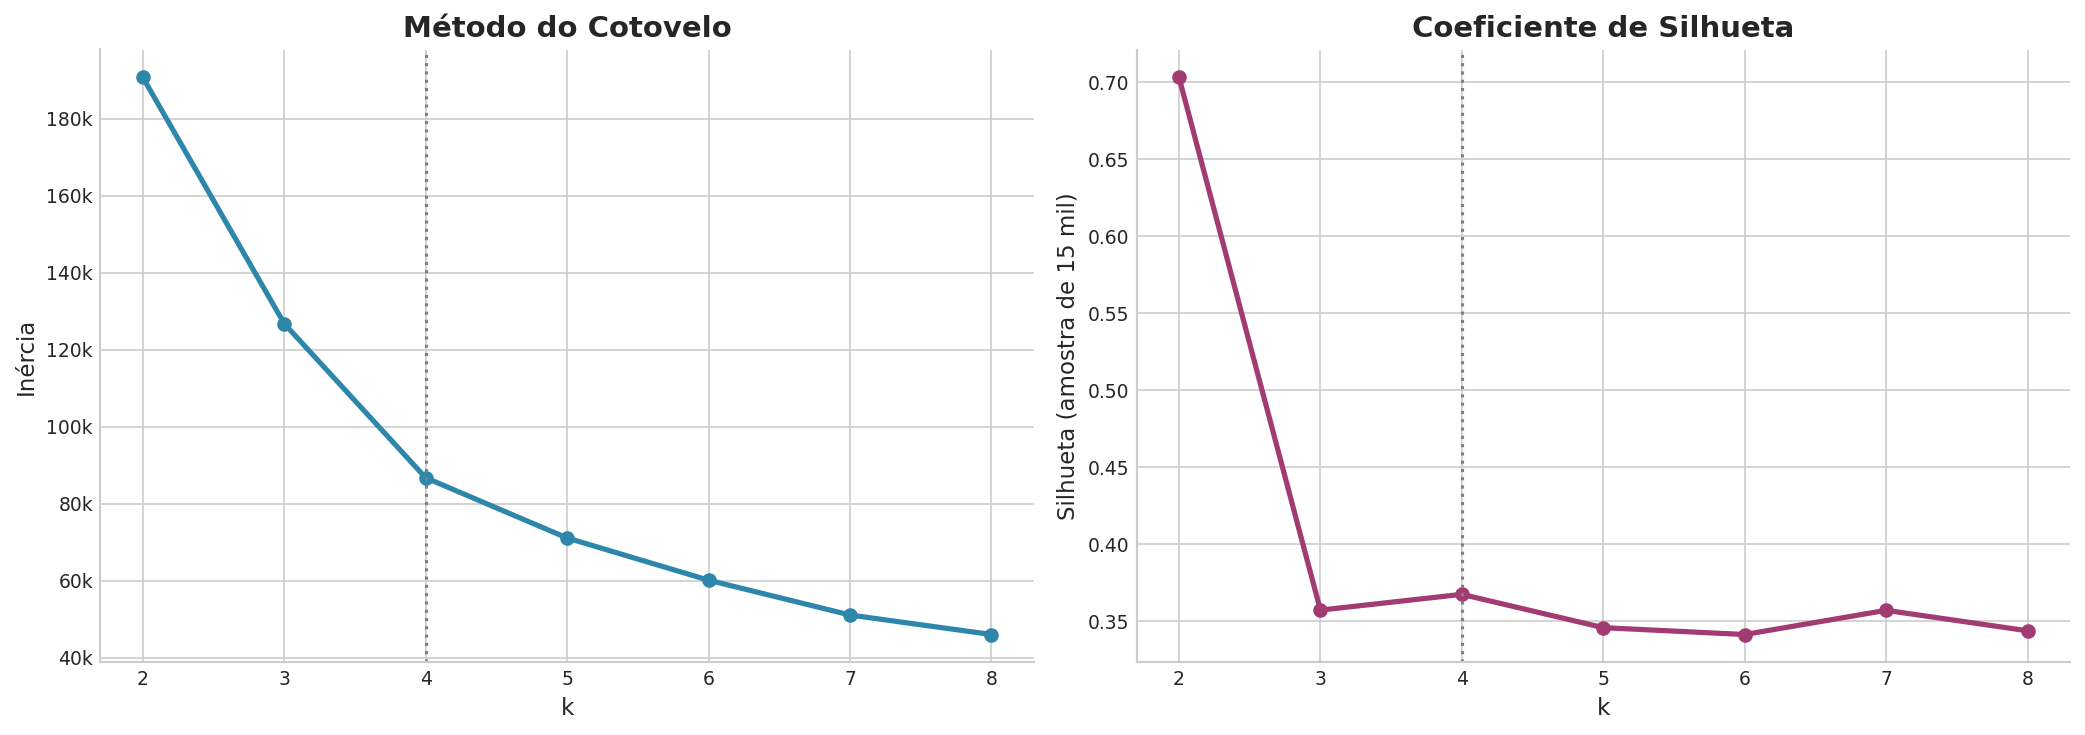

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(resultados['k'], resultados['inercia'], color=COLORS['primary'], linewidth=2.5, marker='o')
axes[0].axvline(N_CLUSTERS_RFM, color='gray', linestyle=':', linewidth=1.5)
axes[0].set_title('Método do Cotovelo')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inércia')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}k'))

axes[1].plot(resultados['k'], resultados['silhueta'], color=COLORS['secondary'], linewidth=2.5, marker='o')
axes[1].axvline(N_CLUSTERS_RFM, color='gray', linestyle=':', linewidth=1.5)
axes[1].set_title('Coeficiente de Silhueta')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhueta (amostra de 15 mil)')

plt.tight_layout()
save_fig('05_escolha_k')
plt.show()

**Leitura:** k=2 tem a maior silhueta, mas só separa quem comprou mais de uma vez de quem comprou uma vez — algo que já sabemos sem modelo. A partir de k=3, a curva de inércia dobra em k=4 e a silhueta de k=4 é a maior entre os k≥3. Por isso sigo com **k=4** (`N_CLUSTERS_RFM` em `src/config.py`).

## 4. Treinamento e Perfil dos Segmentos

In [8]:
kmeans = KMeans(n_clusters=N_CLUSTERS_RFM, n_init=10, random_state=42)
rfm['cluster'] = kmeans.fit_predict(X)

perfil = (
    rfm.groupby('cluster')
    .agg(
        clientes=('customer_unique_id', 'count'),
        recencia_media=('recency', 'mean'),
        frequencia_media=('frequency', 'mean'),
        valor_medio=('monetary', 'mean'),
        valor_mediano=('monetary', 'median'),
        receita=('monetary', 'sum'),
    )
)
perfil['pct_clientes'] = perfil['clientes'] / perfil['clientes'].sum() * 100
perfil['pct_receita'] = perfil['receita'] / perfil['receita'].sum() * 100
display(perfil.round(1))

,clientes,recencia_media,frequencia_media,valor_medio,valor_mediano,receita,pct_clientes,pct_receita
cluster,,,,,,,,
0,31030,154.30,1.00,44.40,43.80,"1,378,146.10",33.20,10.40
1,27147,425.90,1.00,110.00,82.00,"2,984,872.40",29.10,22.60
2,2801,219.80,2.10,260.10,182.10,"728,408.80",3.00,5.50
3,32380,160.80,1.00,251.10,159.00,"8,130,070.90",34.70,61.50


Os números dos clusters mudam entre execuções do K-Means, então os nomes são dados por regra, a partir do perfil:
1. o cluster com maior frequência média são os **Recorrentes**;
2. dos restantes, o de maior recência média (compraram há mais tempo) são os **Inativos**;
3. dos dois que sobram, o de maior valor médio são os **Recentes de alto valor** e o outro os **Recentes de baixo valor**.

In [9]:
restantes = perfil.copy()
nomes = {}
c = restantes['frequencia_media'].idxmax(); nomes[c] = 'Recorrentes'; restantes = restantes.drop(c)
c = restantes['recencia_media'].idxmax(); nomes[c] = 'Inativos'; restantes = restantes.drop(c)
c = restantes['valor_medio'].idxmax(); nomes[c] = 'Recentes de alto valor'; restantes = restantes.drop(c)
nomes[restantes.index[0]] = 'Recentes de baixo valor'

ordem_segmentos = ['Recorrentes', 'Recentes de alto valor', 'Recentes de baixo valor', 'Inativos']
cores_segmentos = dict(zip(ordem_segmentos, [COLORS['secondary'], COLORS['primary'], '#44BBA4', '#9E9E9E']))

rfm['segment'] = rfm['cluster'].map(nomes)
perfil = perfil.rename(index=nomes).reindex(ordem_segmentos)
perfil.index.name = 'segmento'

display(
    perfil.drop(columns='receita')
    .style
    .format({'clientes': '{:,.0f}', 'recencia_media': '{:.0f} dias', 'frequencia_media': '{:.2f}',
             'valor_medio': 'R$ {:,.2f}', 'valor_mediano': 'R$ {:,.2f}',
             'pct_clientes': '{:.1f}%', 'pct_receita': '{:.1f}%'})
    .background_gradient(subset=['pct_receita'], cmap='Blues')
)

,clientes,recencia_media,frequencia_media,valor_medio,valor_mediano,pct_clientes,pct_receita
segmento,,,,,,,
Recorrentes,"2,801",220 dias,2.11,R$ 260.05,R$ 182.10,3.0%,5.5%
Recentes de alto valor,"32,380",161 dias,1.00,R$ 251.08,R$ 159.00,34.7%,61.5%
Recentes de baixo valor,"31,030",154 dias,1.00,R$ 44.41,R$ 43.75,33.2%,10.4%
Inativos,"27,147",426 dias,1.00,R$ 109.95,R$ 82.00,29.1%,22.6%


  ✓ Figura salva: 05_segmentos_rfm.png


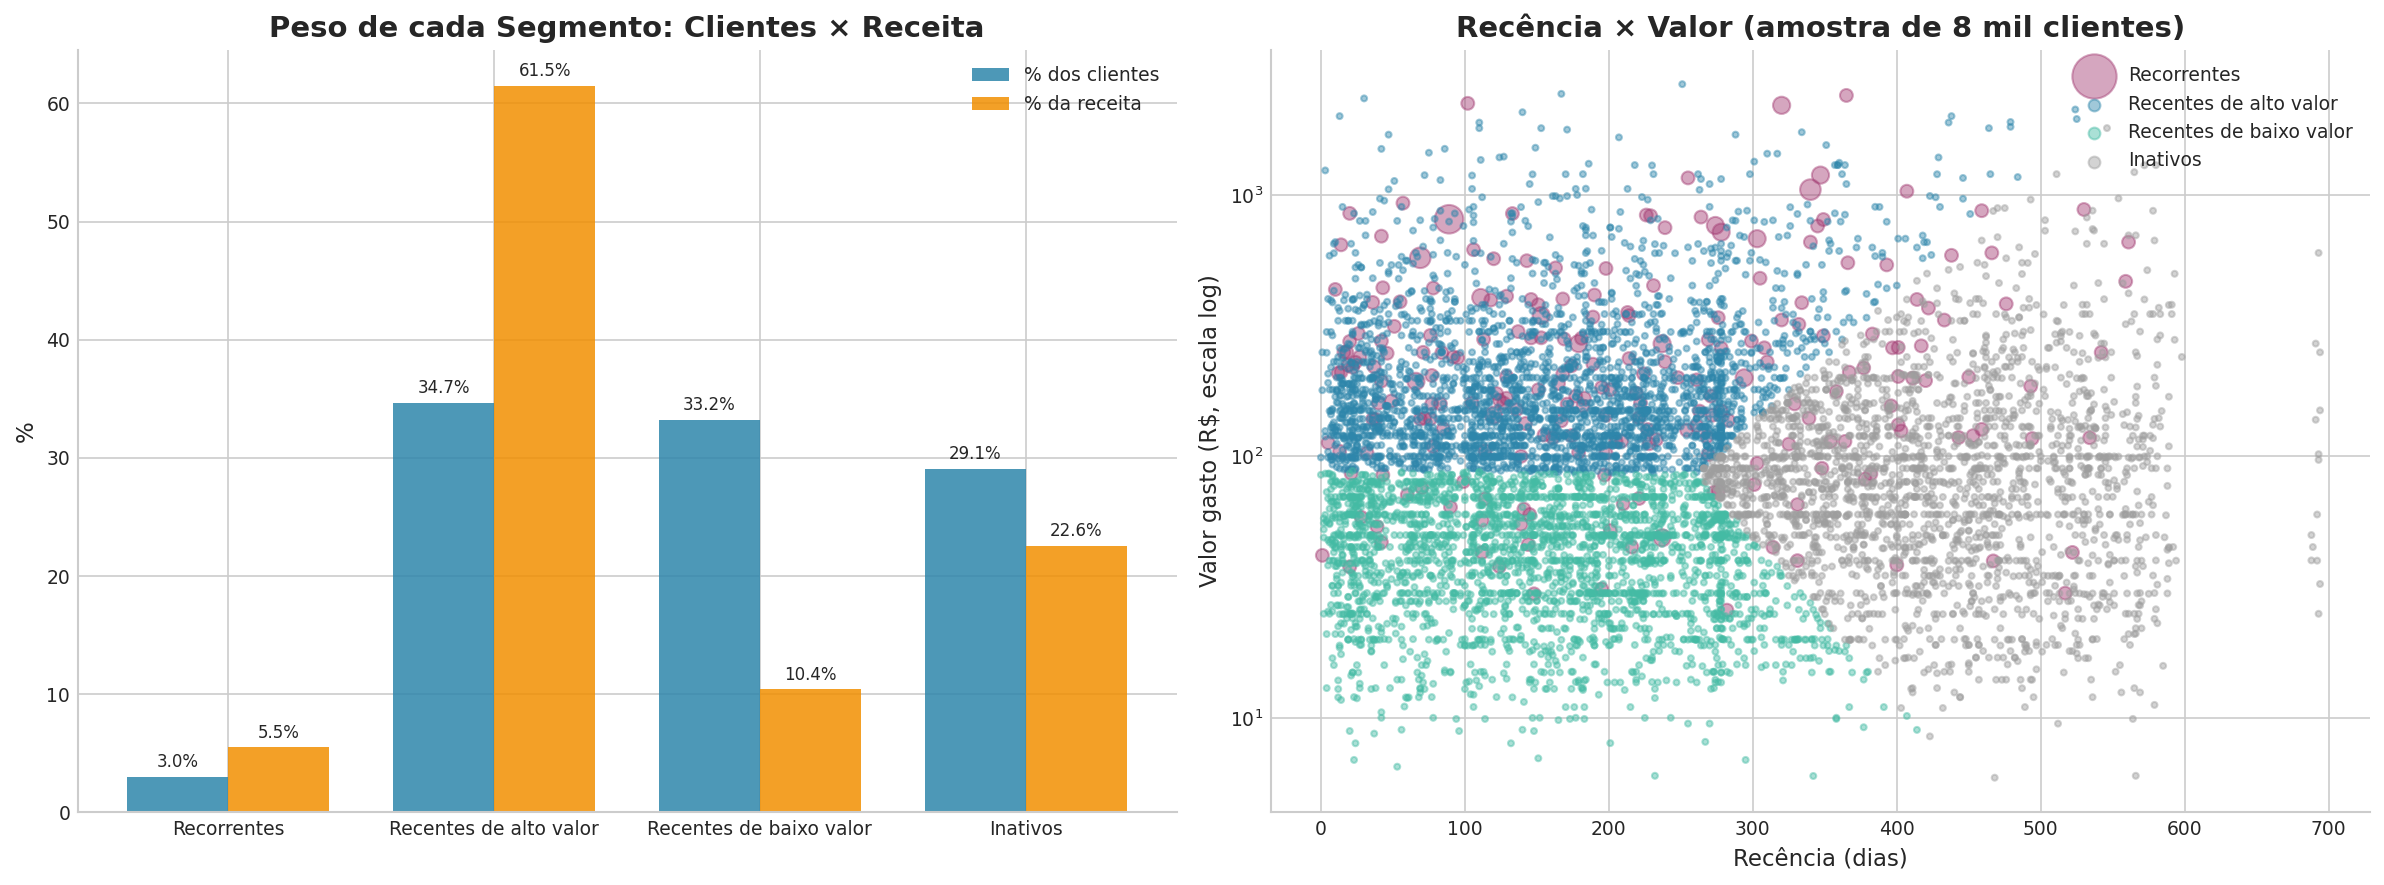

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Participação em clientes × receita
x = np.arange(len(ordem_segmentos))
largura = 0.38
axes[0].bar(x - largura / 2, perfil['pct_clientes'], largura, label='% dos clientes', color=COLORS['primary'], alpha=0.85)
axes[0].bar(x + largura / 2, perfil['pct_receita'], largura, label='% da receita', color=COLORS['accent'], alpha=0.85)
for i, (pc, pr) in enumerate(zip(perfil['pct_clientes'], perfil['pct_receita'])):
    axes[0].text(i - largura / 2, pc + 0.8, f'{pc:.1f}%', ha='center', fontsize=8)
    axes[0].text(i + largura / 2, pr + 0.8, f'{pr:.1f}%', ha='center', fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(ordem_segmentos)
axes[0].set_title('Peso de cada Segmento: Clientes × Receita')
axes[0].set_ylabel('%')
axes[0].legend()

# Recência × valor (amostra para não saturar o gráfico)
amostra_plot = rfm.sample(8_000, random_state=42)
for seg in ordem_segmentos:
    s = amostra_plot[amostra_plot['segment'] == seg]
    axes[1].scatter(s['recency'], s['monetary'], s=8 + (s['frequency'] - 1) * 30,
                    alpha=0.45, color=cores_segmentos[seg], label=seg)
axes[1].set_yscale('log')
axes[1].set_title('Recência × Valor (amostra de 8 mil clientes)')
axes[1].set_xlabel('Recência (dias)')
axes[1].set_ylabel('Valor gasto (R$, escala log)')
axes[1].legend(markerscale=2)

plt.tight_layout()
save_fig('05_segmentos_rfm')
plt.show()

  ✓ Figura salva: 05_perfil_segmentos.png


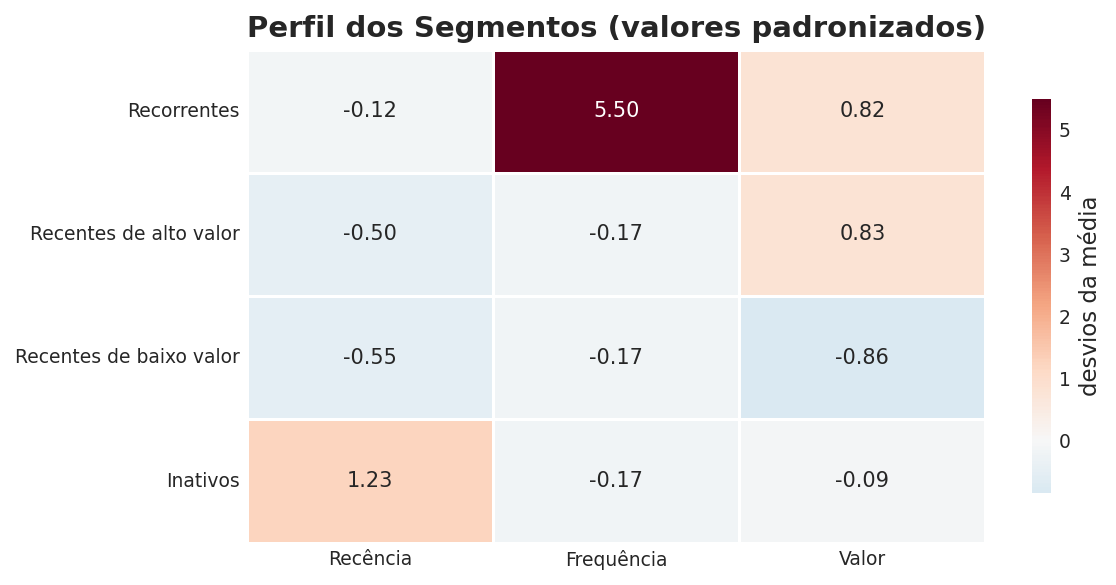

In [11]:
# Perfil médio de cada segmento em escala padronizada (0 = média da base)
perfil_z = (
    pd.DataFrame(X, columns=['Recência', 'Frequência', 'Valor'])
    .assign(segment=rfm['segment'].values)
    .groupby('segment')
    .mean()
    .reindex(ordem_segmentos)
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(perfil_z, annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8, 'label': 'desvios da média'})
ax.set_title('Perfil dos Segmentos (valores padronizados)')
ax.set_ylabel('')
plt.tight_layout()
save_fig('05_perfil_segmentos')
plt.show()

## 5. Segmentos × Satisfação e Categoria

Cruzo os segmentos com a nota de avaliação e a categoria da compra para ver se há algo além de RFM separando os grupos.

In [12]:
pedidos_seg = delivered.merge(rfm[['customer_unique_id', 'segment']], on='customer_unique_id', how='left')

nota_seg = pedidos_seg.groupby('segment')['review_score'].mean().reindex(ordem_segmentos)
print('Nota média de avaliação por segmento:')
for seg, nota in nota_seg.items():
    print(f'  {seg:<25} {nota:.2f}')

top_cat_seg = (
    pedidos_seg.groupby(['segment', 'main_category'])['order_id']
    .count()
    .reset_index()
    .sort_values(['segment', 'order_id'], ascending=[True, False])
    .groupby('segment')
    .head(3)
)
print('\nTop 3 categorias por segmento (nº de pedidos):')
for seg in ordem_segmentos:
    cats = top_cat_seg[top_cat_seg['segment'] == seg]
    print(f'  {seg:<25} ' + ', '.join(f'{c} ({n:,})' for c, n in zip(cats['main_category'], cats['order_id'])))

Nota média de avaliação por segmento:
  Recorrentes               4.22
  Recentes de alto valor    4.07
  Recentes de baixo valor   4.18
  Inativos                  4.22

Top 3 categorias por segmento (nº de pedidos):
  Recorrentes               bed_bath_table (836), sports_leisure (567), furniture_decor (557)
  Recentes de alto valor    watches_gifts (3,162), health_beauty (3,098), bed_bath_table (2,687)
  Recentes de baixo valor   health_beauty (2,903), bed_bath_table (2,833), telephony (2,313)
  Inativos                  bed_bath_table (2,884), sports_leisure (2,235), health_beauty (2,138)


## 6. Salvando os Segmentos

In [13]:
save_processed(rfm, 'rfm')

  ✓ Salvo: data/processed/rfm_segments.parquet (93,358 linhas)


## 7. Sumário e Recomendações

| Segmento | Clientes | % receita | Recência média | Valor médio | Nota média |
|----------|----------|-----------|----------------|-------------|------------|
| Recorrentes | 2.801 (3,0%) | 5,5% | 220 dias | R$ 260,10 | 4,22 |
| Recentes de alto valor | 32.380 (34,7%) | 61,5% | 161 dias | R$ 251,10 | 4,07 |
| Recentes de baixo valor | 31.030 (33,2%) | 10,4% | 154 dias | R$ 44,40 | 4,18 |
| Inativos | 27.147 (29,1%) | 22,6% | 426 dias | R$ 110,00 | 4,22 |

### O que eu tiro daqui
- **Frequência quase não separa ninguém.** 97% dos clientes compraram uma vez, então o modelo acabou separando os grupos principalmente por recência e valor. Os Recorrentes formam um grupo à parte, mas pequeno: 3% dos clientes e 5,5% da receita.
- **Um terço da base sustenta quase dois terços da receita.** Os Recentes de alto valor são o grupo mais importante — e, curiosamente, o que dá a nota mais baixa (4,07). Vale investigar se isso vem do tipo de produto (relógios e presentes, beleza) ou da entrega; o notebook 06 olha para isso.
- **Os Inativos ainda representam 22,6% da receita histórica.** São clientes que compraram há mais de um ano em média; reativar uma parte deles tende a sair mais barato que adquirir clientes novos.

### Ações sugeridas por segmento
| Segmento | Ação |
|----------|------|
| Recorrentes | programa de fidelidade / benefícios para manter a recompra |
| Recentes de alto valor | pós-venda caprichado e recomendação de produtos relacionados para provocar a segunda compra |
| Recentes de baixo valor | cupom de frete ou kit para aumentar o ticket na próxima compra |
| Inativos | campanha de reativação com oferta nas categorias que compraram |

### Limitações
- Clusters do K-Means são esféricos e sensíveis à escala; com uma variável quase constante (frequência), outros métodos (regras por quantis de RFM, por exemplo) poderiam gerar segmentos igualmente úteis.
- O dataset cobre só ~2 anos e é uma amostra da Olist; a taxa de recompra real da plataforma pode ser diferente.

### Próximo Notebook
`06_analise_entregas.ipynb` — prazos de entrega por estado e o efeito do atraso na nota de avaliação.